In [1]:
import gzip
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier

from sktime.classification.kernel_based import RocketClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
with gzip.open("ts_normalized.pkl.gz", "rb") as f:
    ts = pickle.load(f)

for df in ts:
    if 'id' in df.columns:
        df.drop(columns=['id'], inplace=True)  # inutile
    if 'non-wear_flag' in df.columns:
        df.drop(columns=['non-wear_flag'], inplace=True)
    if 'weekday' in df.columns:
        df.drop(columns=['weekday'], inplace=True)
    if 'quarter' in df.columns:
        df.drop(columns=['quarter'], inplace=True)
    if 'relative_date_PCIAT' in df.columns:
        df.drop(columns=['relative_date_PCIAT'], inplace=True)

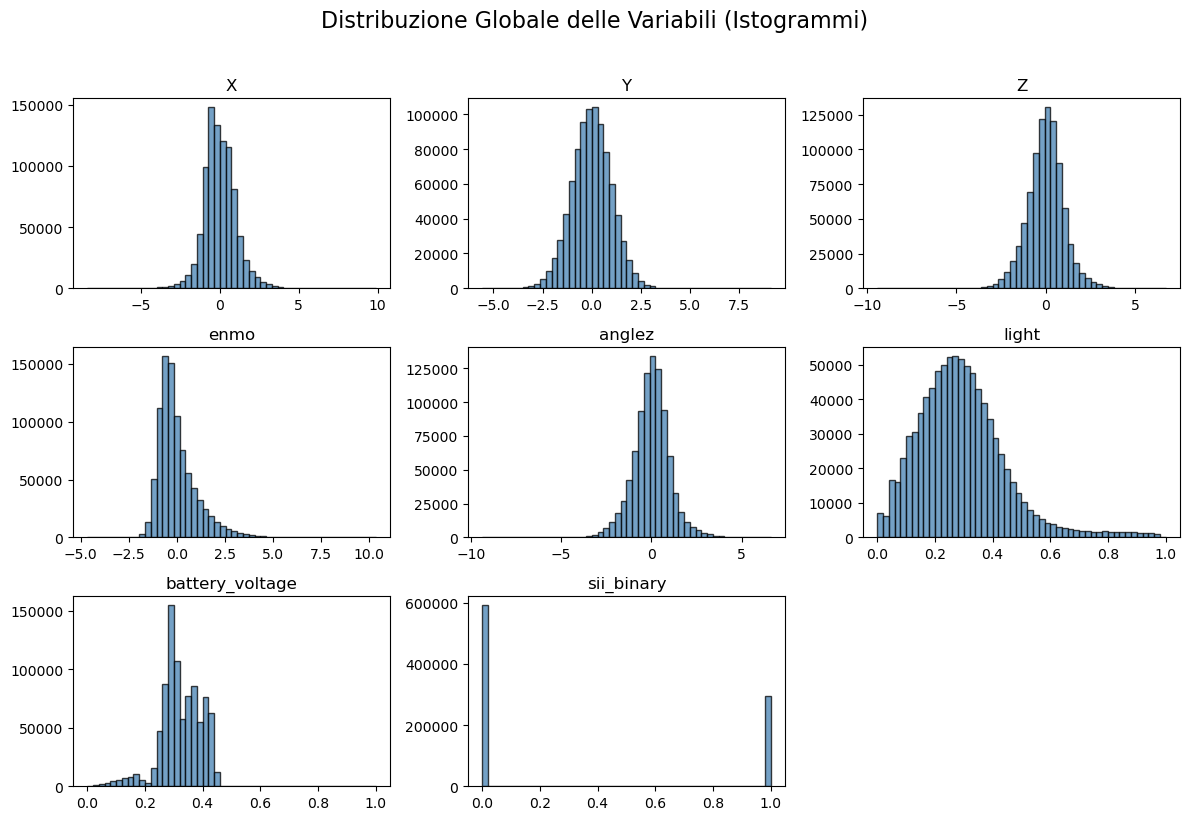

In [16]:
ts_globale = pd.concat(ts, ignore_index=True)

# Opzionale: campionamento per velocizzare la generazione grafica in caso di dataset massivi.
# Se si desidera analizzare il 100% dei dati, lasciare frac=1.0.
df_plot = ts_globale.sample(frac=1.0, random_state=222)

# ==========================================
# 3. Visualizzazione tramite Istogrammi
# ==========================================
# Viene creata una griglia automatica in base al numero di colonne
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black',
             grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili (Istogrammi)",
             y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

In [3]:

X_list = []
y_list = []

for df in ts:
    # y è l'ultima colonna del DataFrame
    y_list.append(df.iloc[0, -1])

    # X contiene tutte le colonne tranne l'ultima
    df_features = df.iloc[:, :-1]
    X_list.append(df_features.values)

y = np.array(y_list)

array_norm = np.array(X_list)

X_sktime_norm = np.transpose(array_norm, (0, 2, 1))

X_train, X_test, y_train, y_test = train_test_split(
    X_sktime_norm,
    y,
    test_size=0.3,
    random_state=222,
    stratify=y
)

# 4. Verifica delle dimensioni
print("--- Dimensioni dei Dataset ---")
print(f"X_train shape: {X_train.shape} (Istanze, Variabili, Timepoints)")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

--- Dimensioni dei Dataset ---
X_train shape: (3105, 7, 200) (Istanze, Variabili, Timepoints)
X_test shape:  (1332, 7, 200)
y_train shape: (3105,)
y_test shape:  (1332,)


Accuracy: 0.64
Precision: 0.61
Recall: 0.64
F1: 0.62

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74       888
           1       0.44      0.33      0.37       444

    accuracy                           0.64      1332
   macro avg       0.57      0.56      0.56      1332
weighted avg       0.61      0.64      0.62      1332



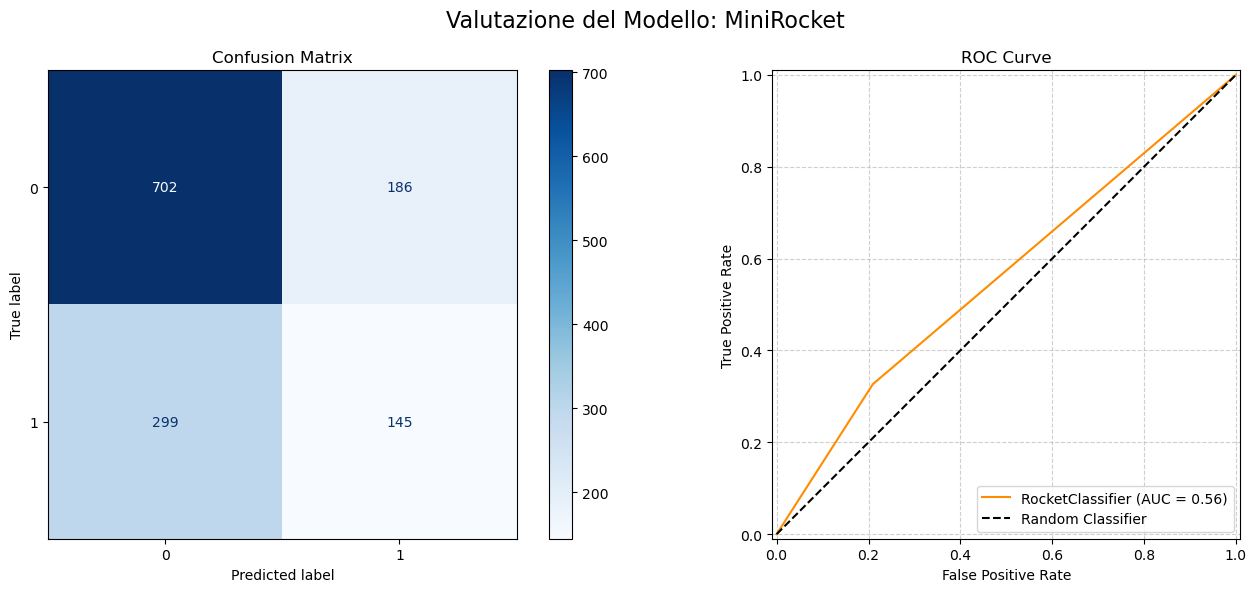

In [6]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)

minirocket = RocketClassifier(
    rocket_transform="minirocket", random_state=222, n_jobs=-1
)

# Assicurarsi che X_train sia nel formato supportato da sktime (es. array NumPy 3D [n_istanze, n_canali, n_timepoints])
minirocket.fit(X_train, y_train)

# 2. Predizione
y_pred = minirocket.predict(X_test)
# Estrazione delle probabilità necessaria per la curva ROC
y_proba = minirocket.predict_proba(X_test)

# 3. Valutazione tramite metriche di performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.2f}")
print(f"Recall: {recall_score(y_test, y_pred, average='weighted'):.2f}")
print(f"F1: {f1_score(y_test, y_pred, average='weighted'):.2f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 4. Generazione dei Grafici (1 riga, 2 colonne)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Valutazione del Modello: MiniRocket", fontsize=16)

# --- Grafico 1: Matrice di Confusione ---
cm = confusion_matrix(y_test, y_pred)
disp_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=minirocket.classes_)
disp_cm.plot(ax=axes[0], cmap="Blues", colorbar=True)
axes[0].set_title("Confusion Matrix")
axes[0].grid(False)

# --- Grafico 2: Curva ROC ---
n_classes = len(minirocket.classes_)

if n_classes == 2:
    # Caso Binario
    RocCurveDisplay.from_estimator(
        minirocket, X_test, y_test, ax=axes[1], color="darkorange"
    )
    axes[1].plot([0, 1], [0, 1], "k--", label="Random Classifier")
else:
    # Caso Multiclasse (Strategia One-vs-Rest)
    y_test_bin = label_binarize(y_test, classes=minirocket.classes_)

    for i in range(n_classes):
        RocCurveDisplay.from_predictions(
            y_test_bin[:, i],
            y_proba[:, i],
            name=f"Classe {minirocket.classes_[i]}",
            ax=axes[1]
        )
    axes[1].plot([0, 1], [0, 1], "k--", label="Random")

axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.6)

# Ottimizzazione e visualizzazione
plt.tight_layout()
plt.show()

In [19]:
'''import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

# 2. Configurazione della Validazione Incrociata
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 3. Griglie Separate per Euclidea e DTW
param_grid_euc = {
    'distance': ['euclidean'],
    'n_neighbors': [1, 10, 55, 100]
}

param_grid_dtw = {
    'distance': ['dtw'],
    'n_neighbors': [1, 10, 55, 100],
    'distance_params': [
        {"window": 0.01},
        {"window": 0.10},
        {"window": 0.20}
    ]
}

# 4. Inizializzazione Classificatori Base (n_jobs=1 per evitare oversubscription)
knn_base_euc = KNeighborsTimeSeriesClassifier(n_jobs=1)
knn_base_dtw = KNeighborsTimeSeriesClassifier(n_jobs=1)

# Inizializzazione di due Grid Search separate con scoring='f1_macro'
grid_search_euc = GridSearchCV(
    estimator=knn_base_euc, param_grid=param_grid_euc, cv=cv_strategy,
    scoring='f1_macro', n_jobs=-1, verbose=1
)

grid_search_dtw = GridSearchCV(
    estimator=knn_base_dtw, param_grid=param_grid_dtw, cv=cv_strategy,
    scoring='f1_macro', n_jobs=-1, verbose=1
)

# 5. Esecuzione delle Ricerche sull'intero Train Set
print(f"--- Ottimizzazione KNN EUCLIDEO ({len(X_train)} istanze) ---")
grid_search_euc.fit(X_train, y_train)
best_euc = grid_search_euc.best_estimator_
print(f"Migliori Parametri Euclidei: {grid_search_euc.best_params_}")
print(f"F1 Macro CV (train set): {grid_search_euc.best_score_:.4f}\n")

print(f"--- Ottimizzazione KNN DTW ({len(X_train)} istanze) ---")
grid_search_dtw.fit(X_train, y_train)
best_dtw = grid_search_dtw.best_estimator_
print(f"Migliori Parametri DTW: {grid_search_dtw.best_params_}")
print(f"F1 Macro CV (train set): {grid_search_dtw.best_score_:.4f}\n")

# 6. Valutazione sul Test Set
print("\nCalcolo predizioni sul Test Set (Euclideo)...")
y_pred_euc = best_euc.predict(X_test)

print("Calcolo predizioni sul Test Set (DTW)...")
y_pred_dtw = best_dtw.predict(X_test)

print("\n=========================================")
print(f" RISULTATI FINALI SUL TEST SET ({len(X_test)} istanze)")
print("=========================================")

print("\n>>> Modello KNN - EUCLIDEO <<<")
print(f"F1 Macro: {f1_score(y_test, y_pred_euc, average='macro'):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_euc):.4f}")
print(classification_report(y_test, y_pred_euc))

print("\n>>> Modello KNN - DTW <<<")
print(f"F1 Macro: {f1_score(y_test, y_pred_dtw, average='macro'):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dtw):.4f}")
print(classification_report(y_test, y_pred_dtw))

# 7. Confronto Dettagliato Window vs Itakura (Analisi Interna CV)
risultati_cv_dtw = pd.DataFrame(grid_search_dtw.cv_results_)

def identifica_vincolo(params_dict):
    if isinstance(params_dict, dict):
        if 'window' in params_dict:
            return f"Window ({params_dict['window']})"
        elif 'itakura_max_slope' in params_dict:
            return f"Itakura ({params_dict['itakura_max_slope']})"
    return "Nessuno"

risultati_cv_dtw['Tipo Vincolo'] = risultati_cv_dtw['param_distance_params'].apply(identifica_vincolo)
colonne_display = ['param_n_neighbors', 'Tipo Vincolo', 'mean_test_score', 'std_test_score']
tabella_confronto_dtw = risultati_cv_dtw[colonne_display].sort_values(by='mean_test_score', ascending=False)

print("\n--- Confronto Dettagliato DTW (Train Set CV): Itakura vs Window ---")
print(tabella_confronto_dtw.to_string(index=False))

cm_euc = confusion_matrix(y_test, y_pred_euc)
cm_dtw = confusion_matrix(y_test, y_pred_dtw)

# 8. Configurazione dell'area di tracciamento (1 riga, 2 colonne)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Confronto Matrici di Confusione: KNN Euclideo vs KNN DTW", fontsize=16, y=1.05)

# Plot della Matrice per il Modello Euclideo
disp_euc = ConfusionMatrixDisplay(
    confusion_matrix=cm_euc,
    display_labels=best_euc.classes_
)
disp_euc.plot(ax=axes[0], cmap='Blues', colorbar=True)
axes[0].set_title('Modello: KNN - Distanza Euclidea')
axes[0].grid(False) 

# Plot della Matrice per il Modello DTW
disp_dtw = ConfusionMatrixDisplay(
    confusion_matrix=cm_dtw,
    display_labels=best_dtw.classes_
)
disp_dtw.plot(ax=axes[1], cmap='Greens', colorbar=True)
axes[1].set_title('Modello: KNN - Distanza DTW')
axes[1].grid(False)

# Ottimizzazione degli spazi e visualizzazione
plt.tight_layout()
plt.show()'''

'import pandas as pd\nimport matplotlib.pyplot as plt\nfrom sklearn.model_selection import StratifiedKFold, GridSearchCV\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score\n\n# 2. Configurazione della Validazione Incrociata\ncv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)\n\n# 3. Griglie Separate per Euclidea e DTW\nparam_grid_euc = {\n    \'distance\': [\'euclidean\'],\n    \'n_neighbors\': [1, 10, 55, 100]\n}\n\nparam_grid_dtw = {\n    \'distance\': [\'dtw\'],\n    \'n_neighbors\': [1, 10, 55, 100],\n    \'distance_params\': [\n        {"window": 0.01},\n        {"window": 0.10},\n        {"window": 0.20}\n    ]\n}\n\n# 4. Inizializzazione Classificatori Base (n_jobs=1 per evitare oversubscription)\nknn_base_euc = KNeighborsTimeSeriesClassifier(n_jobs=1)\nknn_base_dtw = KNeighborsTimeSeriesClassifier(n_jobs=1)\n\n# Inizializzazione di due Grid Search separate con scoring=\'f1_macro\'\ngrid_s

In [7]:
from sklearn.metrics import classification_report, accuracy_score, f1_score
# Assumendo l'importazione del classificatore da aeon o sktime
# from aeon.classification.distance_based import KNeighborsTimeSeriesClassifier
X_list_knn = []
y_list_knn = []
with gzip.open("ts_datasetwise_transformed_paa.pkl.gz", "rb") as f:
    ts_knn = pickle.load(f)
# Si assume che 'ts' sia la lista di DataFrame caricata in precedenza
for df in ts:
    # y è l'ultima colonna del DataFrame
    y_list_knn.append(df.iloc[0, -1])

    # X contiene tutte le colonne tranne l'ultima
    df_features = df.iloc[:, :-1]
    X_list_knn.append(df_features.values)

y = np.array(y_list_knn)
array_norm = np.array(X_list_knn)

# Rimodellamento per sktime/aeon: (n_istanze, n_variabili, n_timepoints)
X_sktime_norm = np.transpose(array_norm, (0, 2, 1))

X_train, X_test, y_train, y_test = train_test_split(
    X_sktime_norm,
    y,
    test_size=0.3,
    random_state=222,
    stratify=y
)
# 1. Inizializzazione dei Classificatori
knn_euc = KNeighborsTimeSeriesClassifier(
    distance='euclidean',
    n_neighbors=1,
    n_jobs=-1
)

knn_dtw = KNeighborsTimeSeriesClassifier(
    distance='dtw',
    n_neighbors=1,
    distance_params={"window": 0.10},
    n_jobs=-1
)

# 2. Addestramento sui dati di training
print("Addestramento KNN Euclideo (k=55)...")
knn_euc.fit(X_train, y_train)

print("Addestramento KNN DTW (k=55, window=0.10)...")
knn_dtw.fit(X_train, y_train)

# 3. Predizione sui dati di test
print("\nCalcolo predizioni sul Test Set...")
y_pred_euc = knn_euc.predict(X_test)
y_pred_dtw = knn_dtw.predict(X_test)

# 4. Valutazione dei modelli
print("\n=========================================")
print(" RISULTATI KNN - DISTANZA EUCLIDEA")
print("=========================================")
print(f"F1 Macro: {f1_score(y_test, y_pred_euc, average='macro'):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_euc):.4f}")
print(classification_report(y_test, y_pred_euc))

print("\n=========================================")
print(" RISULTATI KNN - DISTANZA DTW")
print("=========================================")
print(f"F1 Macro: {f1_score(y_test, y_pred_dtw, average='macro'):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dtw):.4f}")
print(classification_report(y_test, y_pred_dtw))

Addestramento KNN Euclideo (k=55)...
Addestramento KNN DTW (k=55, window=0.10)...

Calcolo predizioni sul Test Set...

 RISULTATI KNN - DISTANZA EUCLIDEA
F1 Macro: 0.5289
Accuracy: 0.5878
              precision    recall  f1-score   support

           0       0.69      0.71      0.70       888
           1       0.37      0.35      0.36       444

    accuracy                           0.59      1332
   macro avg       0.53      0.53      0.53      1332
weighted avg       0.58      0.59      0.58      1332


 RISULTATI KNN - DISTANZA DTW
F1 Macro: 0.5543
Accuracy: 0.6149
              precision    recall  f1-score   support

           0       0.70      0.74      0.72       888
           1       0.41      0.37      0.39       444

    accuracy                           0.61      1332
   macro avg       0.56      0.55      0.55      1332
weighted avg       0.60      0.61      0.61      1332




Calcolo predizioni sul Test Set...

 RISULTATI: KNN - Distanza Euclidea
Accuracy: 0.59
Precision: 0.58
Recall: 0.59
F1: 0.58

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.71      0.70       888
           1       0.37      0.35      0.36       444

    accuracy                           0.59      1332
   macro avg       0.53      0.53      0.53      1332
weighted avg       0.58      0.59      0.58      1332



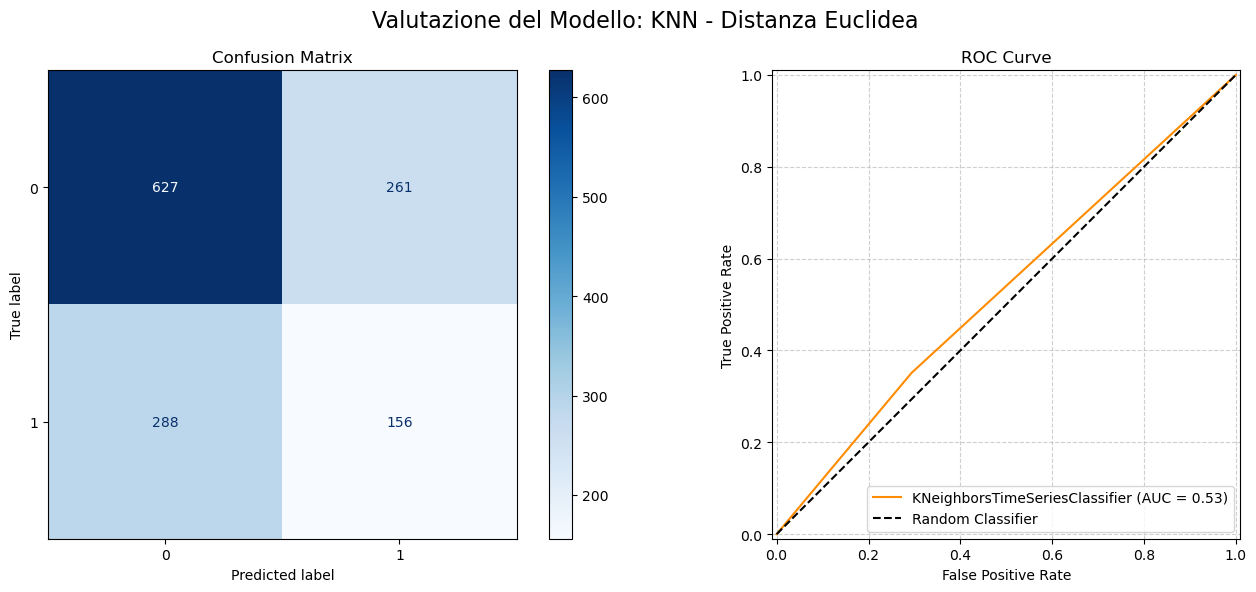


 RISULTATI: KNN - Distanza DTW
Accuracy: 0.61
Precision: 0.60
Recall: 0.61
F1: 0.61

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.74      0.72       888
           1       0.41      0.37      0.39       444

    accuracy                           0.61      1332
   macro avg       0.56      0.55      0.55      1332
weighted avg       0.60      0.61      0.61      1332



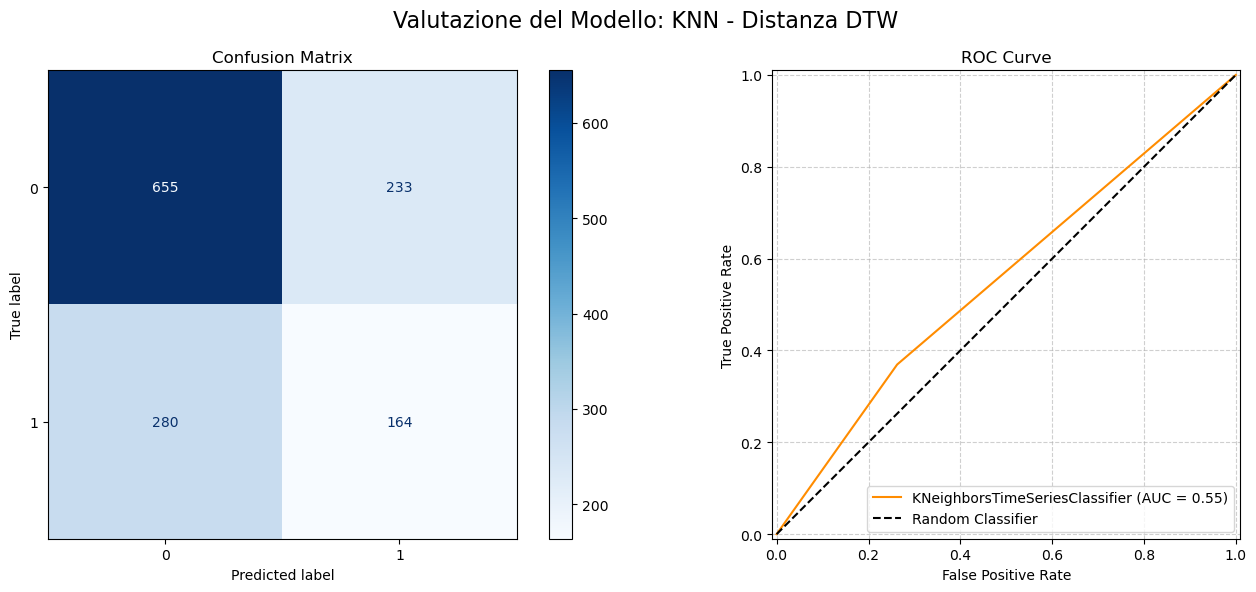

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.preprocessing import label_binarize

# ... [Assumendo che Fase 1 e Fase 2 siano già eseguite come nel codice fornito] ...

# 3. Predizione sui dati di test
print("\nCalcolo predizioni sul Test Set...")
y_pred_euc = knn_euc.predict(X_test)
y_pred_dtw = knn_dtw.predict(X_test)

# Estrazione delle probabilità necessaria per la curva ROC
y_proba_euc = knn_euc.predict_proba(X_test)
y_proba_dtw = knn_dtw.predict_proba(X_test)

# Funzione per generare report e grafici in modo standardizzato


def valuta_e_plotta(modello, nome_modello, X_test, y_test, y_pred, y_proba):
    print(f"\n=========================================")
    print(f" RISULTATI: {nome_modello}")
    print(f"=========================================")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print(
        f"Precision: {precision_score(y_test, y_pred, average='weighted'):.2f}")
    print(f"Recall: {recall_score(y_test, y_pred, average='weighted'):.2f}")
    print(f"F1: {f1_score(y_test, y_pred, average='weighted'):.2f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Generazione dei Grafici (1 riga, 2 colonne)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Valutazione del Modello: {nome_modello}", fontsize=16)

    # --- Grafico 1: Matrice di Confusione ---
    cm = confusion_matrix(y_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=modello.classes_)
    disp_cm.plot(ax=axes[0], cmap="Blues", colorbar=True)
    axes[0].set_title("Confusion Matrix")
    axes[0].grid(False)

    # --- Grafico 2: Curva ROC ---
    n_classes = len(modello.classes_)

    if n_classes == 2:
        # Caso Binario
        RocCurveDisplay.from_estimator(
            modello, X_test, y_test, ax=axes[1], color="darkorange"
        )
        axes[1].plot([0, 1], [0, 1], "k--", label="Random Classifier")
    else:
        # Caso Multiclasse (Strategia One-vs-Rest)
        y_test_bin = label_binarize(y_test, classes=modello.classes_)

        for i in range(n_classes):
            RocCurveDisplay.from_predictions(
                y_test_bin[:, i],
                y_proba[:, i],
                name=f"Classe {modello.classes_[i]}",
                ax=axes[1]
            )
        axes[1].plot([0, 1], [0, 1], "k--", label="Random")

    axes[1].set_title("ROC Curve")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend(loc="lower right")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    # Ottimizzazione e visualizzazione
    plt.tight_layout()
    plt.show()


# 4. Valutazione dei modelli
valuta_e_plotta(knn_euc, "KNN - Distanza Euclidea",
                X_test, y_test, y_pred_euc, y_proba_euc)
valuta_e_plotta(knn_dtw, "KNN - Distanza DTW", X_test,
                y_test, y_pred_dtw, y_proba_dtw)